# Simulating a project

This notebook follows one project through a 25-year simulation and looks at what comes out. It
picks up from [Getting started](../docs/getting-started.md): the same calls, on a project closer to
a real one.

The figures are drawn the way GHE Analysis draws them (it is the application whose kernel the
package runs), with its colours and the wording of its legends: orange for the hourly entering fluid temperature, red for heating, blue for
cooling, green for the building's cooling demand. The code is in `ghestyle.py` and `ghecharts.py`,
next to this notebook.

You need the executable, a licence (see [the documentation](../docs/index.md)) and `matplotlib`.
Run the notebook from the `examples` folder so that it finds the two helper modules. The
[manual of the application](https://www.gheanalysis.com/pages/ghe-analysis-documentation) is the
place to look for the models behind each chart.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyghe as ga
import ghecharts
import ghestyle as ghe
from demo_project import make_project

ghe.use()          # the colours, fonts and axis style of GHE Analysis

## The project

`make_project()` builds a small office building: four heat pumps on a field of twelve boreholes,
100 m each, 6 m apart. The numbers are invented but behave like a real case. The heating load
follows the outdoor temperature and the occupancy of the week, there is a cooling season, and there
is domestic hot water on weekdays. Printed, the project lists the fields of each node with their symbols and units:

In [2]:
p = make_project()
print(p.gshp_system)
print(p.ground_heat_exchanger)
assert p.validate("simulate") == []

GSHPSystem
  system_type = 'Water-water (zone)'
  number_of_heat_pumps (nHP) = 4 HP
  power_of_auxiliary (QAux) = ByMode(heating=8.0 kW, cooling=0.0 kW)
  flow_rate_of_pump_a (VA) = ByMode(heating=300.0 L/min, cooling=300.0 L/min)
  power_of_pump_a (QA) = ByMode(heating=0.0 kW, cooling=0.0 kW)
  flow_rate_of_pump_b (VB) = ByMode(heating=0.0 L/min, cooling=0.0 L/min)
  power_of_pump_b (QB) = ByMode(heating=0.0 kW, cooling=0.0 kW)
  flow_rate_of_pump_c (VC) = (not set)
  power_of_pump_c (QC) = 0.0 kW
GroundHeatExchanger
  ground_thermal_conductivity (λs) = 2.5 W/m·K
  ground_volumetric_capacity (Cs) = 2.2 MJ/m³·K
  mean_surface_temperature (T0) = 8.0 °C
  geothermal_heat_flux (qg) = 60.0 mW/m²
  groundwater_flow (vD) = (not set)
  groundwater_flow_direction (θ) = 0.0 deg.
  active_length (H) = 100.0 m
  burial_depth (D) = 2.0 m
  coordinates: Coordinates
      x = [0 … 18] (12 values) m
      y = [0 … 12] (12 values) m
      az (Az.) = (not set)
      dip (Dip.) = (not set)
      label =

The building's demand over one year, drawn as the application draws it: orange when the building
needs heat, green when it needs cooling.

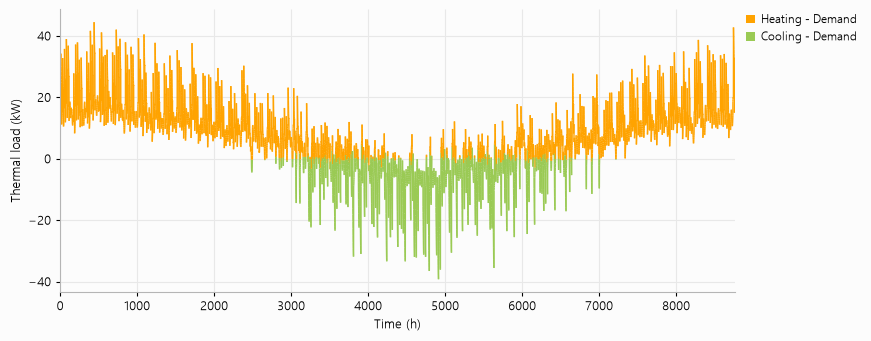

In [3]:
loads = p.building_loads
demand = loads.heating_demand - np.abs(loads.cooling_demand)          # kW, heating positive
hours = np.arange(1, 8761)

fig, ax = ghe.figure()
ghe.signed_line(ax, hours, demand, above=ghe.ORANGE, below=ghe.GREEN)
ax.set_xlim(0, 8760)
ghe.axis_titles(ax, x="Time (h)", y="Thermal load (kW)")
ghe.legend(ax, [(ghe.ORANGE, "Heating - Demand"), (ghe.GREEN, "Cooling - Demand")])

Monthly totals make it plainer. The building is heating-dominated, with a real cooling season, so
the heat balance of the ground is uneven.

heating 80.3 MWh, cooling 21.0 MWh


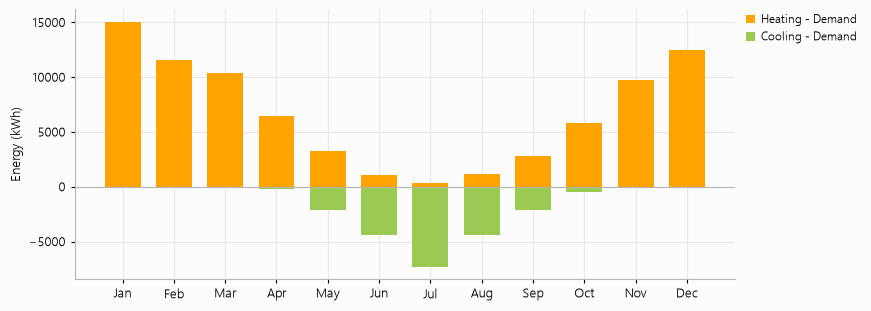

In [4]:
days_in_month = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
edges = np.concatenate([[0], np.cumsum(days_in_month * 24)])
heating_kwh = np.array([loads.heating_demand[a:b].sum() for a, b in zip(edges[:-1], edges[1:])])
cooling_kwh = np.array([np.abs(loads.cooling_demand[a:b]).sum() for a, b in zip(edges[:-1], edges[1:])])
months = np.arange(12)

fig, ax = ghe.figure(8.6, 3.0)
ax.bar(months, heating_kwh, color=ghe.ORANGE, width=0.7)
ax.bar(months, -cooling_kwh, color=ghe.GREEN, width=0.7)
ax.axhline(0, color=ghe.AXIS, linewidth=0.8)
ax.set_xticks(months, ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ghe.axis_titles(ax, y="Energy (kWh)")
ghe.legend(ax, [(ghe.ORANGE, "Heating - Demand"), (ghe.GREEN, "Cooling - Demand")])
print(f"heating {heating_kwh.sum() / 1000:.1f} MWh, cooling {cooling_kwh.sum() / 1000:.1f} MWh")

## Simulating

`series=` lists the hourly series to return. By default only the entering fluid temperature and the
effective COP come back; here it asks for the ones the charts below draw.

In [5]:
r = p.simulate(series=ghecharts.ALL_CHARTS)
print(r)

<SimulationResult ghe simulation: ok>
  iterations = 5, residuals: EFT 0.00045 K, ground load 0.00406 kW
  undisturbed_ground_temperature (Tg) = 9.248 °C
  hourly: auxiliary_load, building_load, effective_borehole_resistance, effective_capacity, effective_cop, entering_fluid_temperature, fluid_temperature_difference, ground_load, heat_pump_load
  minimum_eft = 0.5874127415345675 °C
  maximum_eft = 16.38925457573632 °C
  hours_below_temperature_limit = 0 h
  hours_above_temperature_limit = 0 h
  hours_below_r_cop_range = 0 h
  hours_above_r_cop_range = 0 h
  peak_heat_pump_load = ByMode(heating=39.185416400069705 kW, cooling=-39.19367588669519 kW)
  peak_ground_load = ByMode(heating=-23.731385756055307 W/m, cooling=37.62470215524338 W/m)


The simulation converged in a few iterations and the heat pumps stayed within their temperature
limits. What follows are the eight charts GHE Analysis shows for a simulation, in the same order,
each drawn by a function of `ghecharts.py` from a project and a result.

### Entering fluid temperature

The red line is the heating limit of the heat pumps and the blue one the cooling limit. The orange
trace is every hour and the black one the daily mean. The field cools a little each winter and does
not quite recover in summer, which is what a heating-dominated building does.

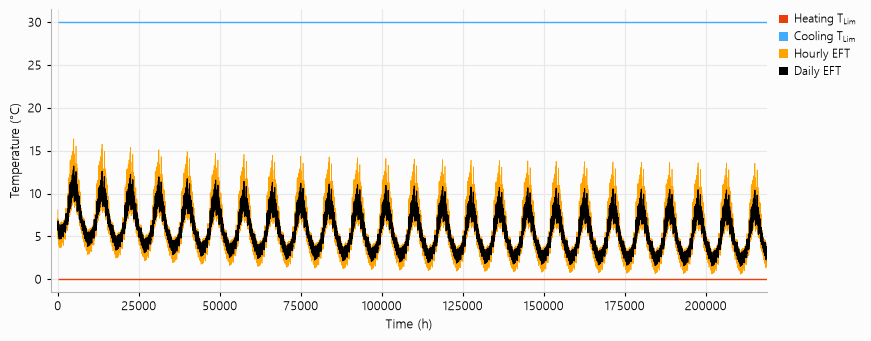

In [6]:
fig = ghecharts.eft_chart(p, r)

### Thermal loads

This chart shows how the demand is covered: the building's demand in orange, the heat pumps in red
and blue, and the auxiliary heating on top of them in lighter red. It covers two years, since 25
would hide the detail. The heat pumps meet the demand almost everywhere, so the red lies on the
orange.

Three calls of `signed_line` draw it, one per curve, each with its two colours for heating and
cooling:

```python
ghe.signed_line(ax, t, demand, ghe.ORANGE, ghe.GREEN)
ghe.signed_line(ax, t, heat_pump + auxiliary, ghe.RED2, ghe.BLUE2)
ghe.signed_line(ax, t, heat_pump, ghe.RED, ghe.BLUE)
```

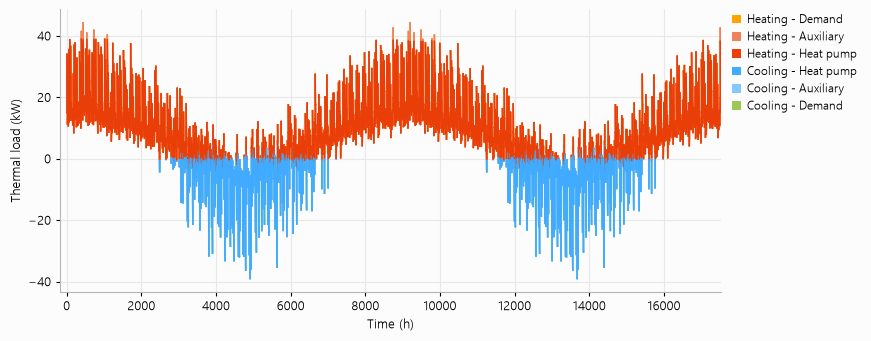

In [7]:
fig = ghecharts.thermal_load_chart(r, start=0, stop=2 * 8760)

### Ground load

What the field exchanges with the ground. Negative (red) is heat taken from the ground in winter,
positive (blue) is heat given to it in summer. The two do not cancel, and the difference is why the
first chart drifts downwards.

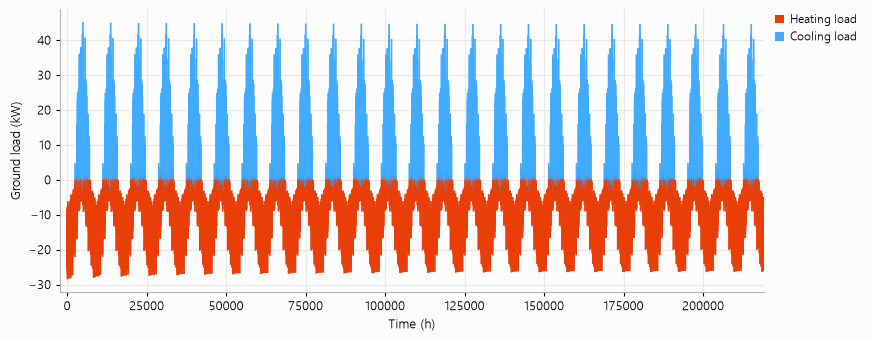

In [8]:
fig = ghecharts.ground_load_chart(r)

### COP and capacity

The chart draws the COP upward in heating and downward in cooling, so that both modes share one
axis. The capacity chart does the same with the power the heat pumps deliver. The kernel's own sign
for the capacity is the opposite of the chart's: the charts of GHE Analysis plot minus the capacity, and so
does `ghecharts`.

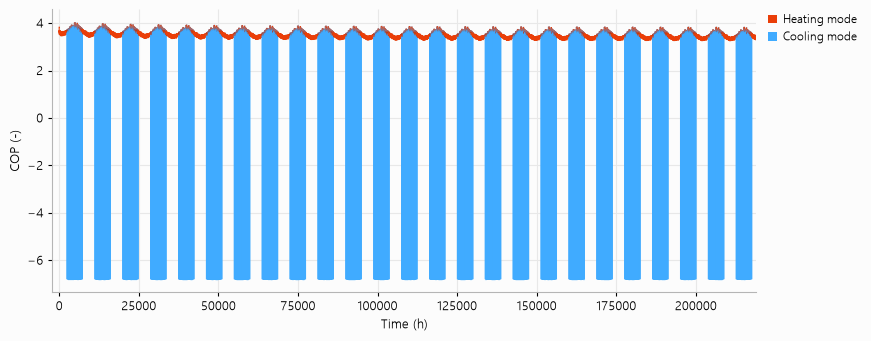

In [9]:
fig = ghecharts.cop_chart(r)

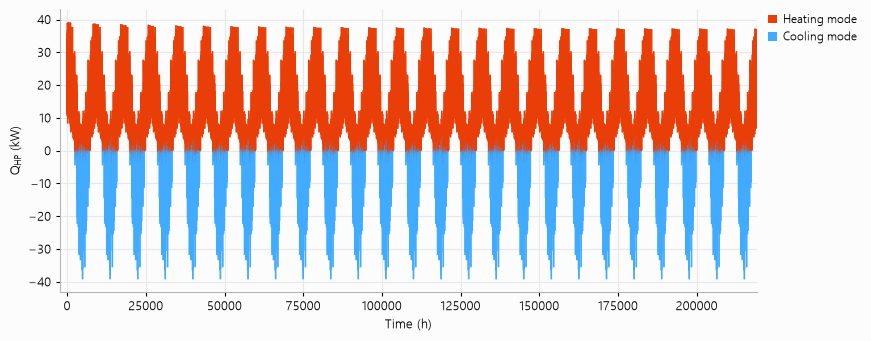

In [10]:
fig = ghecharts.capacity_chart(r)

### Temperature difference and effective resistance

The difference between entering and leaving fluid temperature follows the load. The effective
borehole resistance varies a little with the flow and the fluid temperature at each hour.

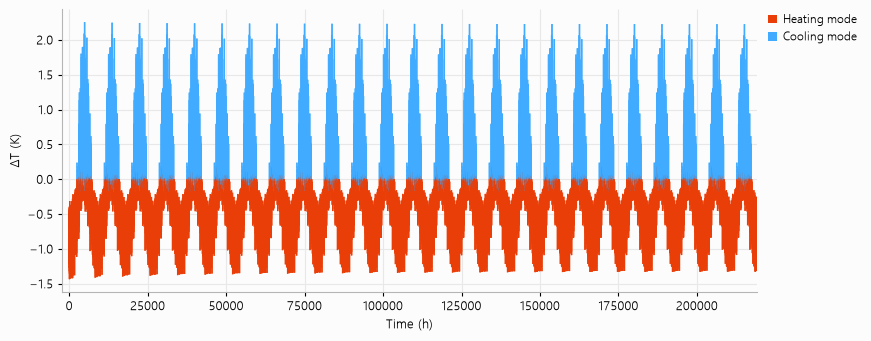

In [11]:
fig = ghecharts.delta_t_chart(r)

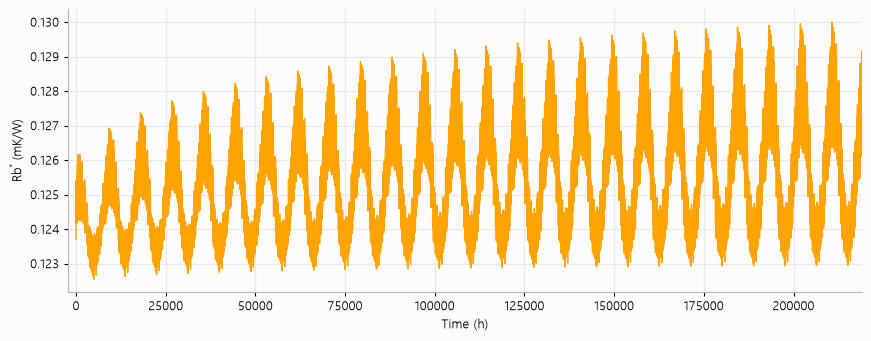

In [12]:
fig = ghecharts.rb_chart(r)

### g-function

The thermal response of the field to a constant heat rate, on a logarithmic time scale. The simulation convolves the loads with this curve. It has its own call,
`compute_gfunction`.

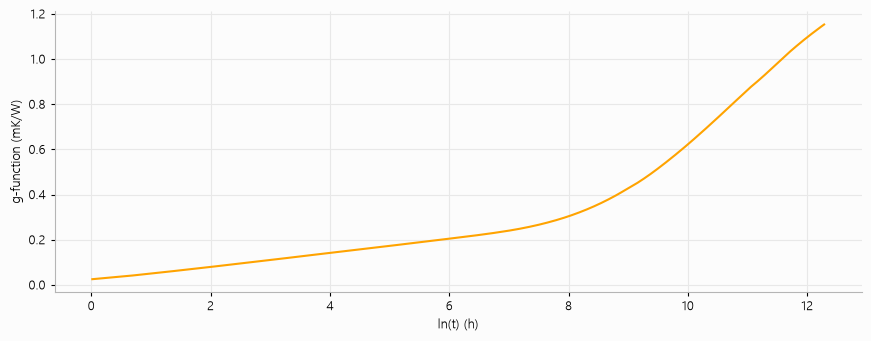

In [13]:
gf = p.compute_gfunction()
fig = ghecharts.gfunction_chart(gf)

## Looking closer

Twenty-five years show the trend and hide the detail, so here is the week around the coldest hour
of the simulation.

coldest hour: 210689 (year 25), 0.59 °C


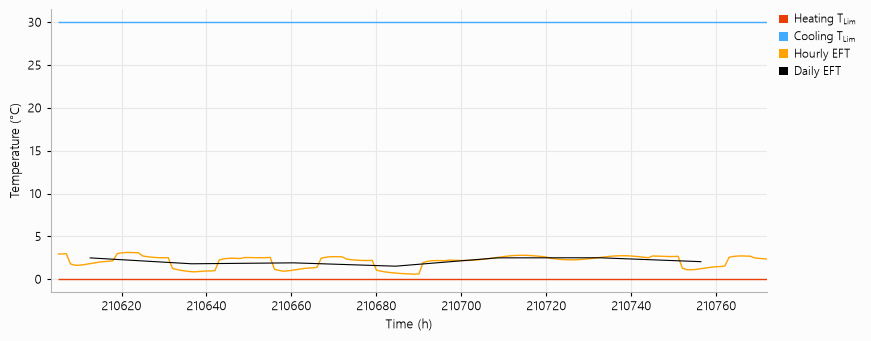

In [14]:
eft = r.hourly.entering_fluid_temperature
coldest = int(np.argmin(eft))
start = max(0, coldest - 84)
print(f"coldest hour: {coldest + 1} (year {coldest // 8760 + 1}), {eft[coldest]:.2f} °C")

fig = ghecharts.eft_chart(p, r, start=start, stop=start + 168)

The same week as thermal load. When the heat pumps cannot keep up, the auxiliary heating appears
as the lighter red above the heat pump line.

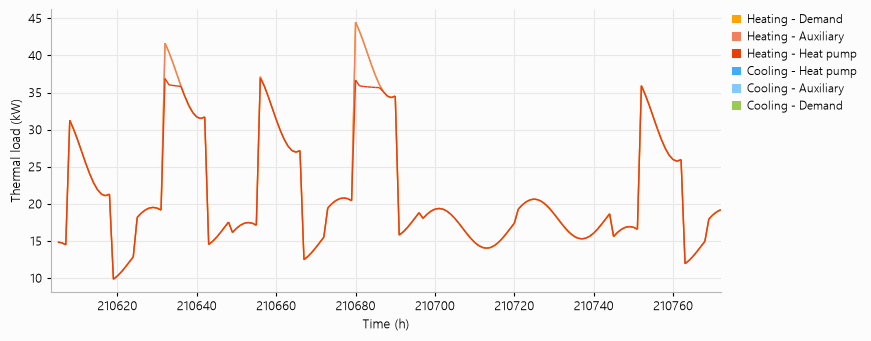

In [15]:
fig = ghecharts.thermal_load_chart(r, start=start, stop=start + 168)

## Year by year

A 25-year simulation shows how the field ages. I cut the entering fluid temperature into years and
keep the coldest and the warmest hour of each. The coldest matters in heating, so it is red and
compared with the heating limit; the warmest matters in cooling, so it is blue.

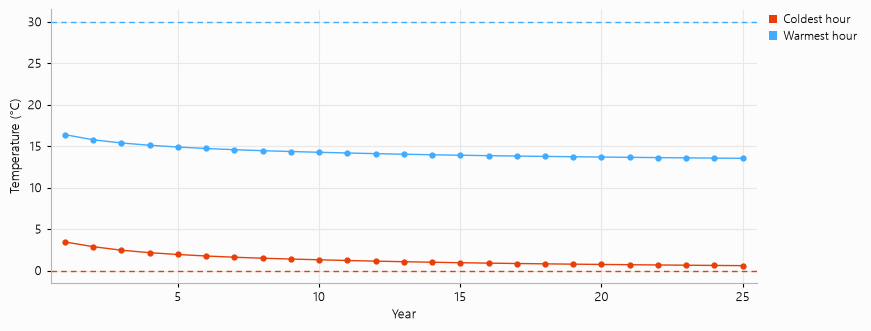

In [16]:
by_year = eft.reshape(25, 8760)
years = np.arange(1, 26)
limit = p.heat_pump_performance.temperature_limit

fig, ax = ghe.figure(8.6, 3.2)
ax.axhline(limit.heating, color=ghe.RED, linewidth=1.0, linestyle=(0, (4, 3)))
ax.axhline(limit.cooling, color=ghe.BLUE, linewidth=1.0, linestyle=(0, (4, 3)))
ax.plot(years, by_year.min(axis=1), color=ghe.RED, marker="o", markersize=3.5)
ax.plot(years, by_year.max(axis=1), color=ghe.BLUE, marker="o", markersize=3.5)
ax.set_xlim(0.5, 25.5)
ghe.axis_titles(ax, x="Year", y="Temperature (°C)")
ghe.legend(ax, [(ghe.RED, "Coldest hour"), (ghe.BLUE, "Warmest hour")])

In [17]:
drop = by_year.min(axis=1)[0] - by_year.min(axis=1)[-1]
print(f"the coldest hour falls by {drop:.2f} K between year 1 and year 25")

the coldest hour falls by 2.86 K between year 1 and year 25


Monthly means smooth out the weather and show the seasons. Year 1 and year 25, one above the
other: the whole curve has moved down, and the summer has not recovered what the winter took.

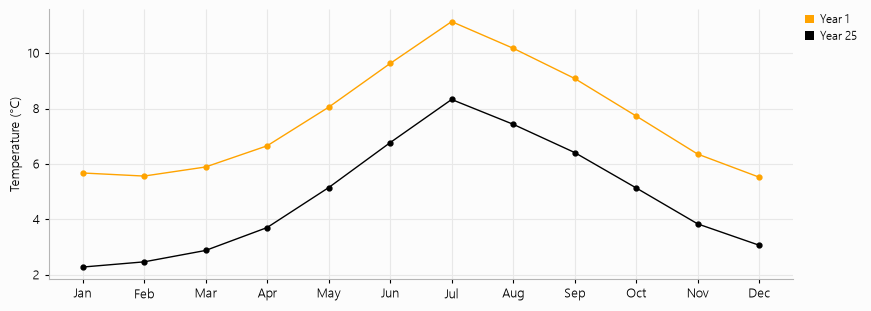

In [18]:
monthly = r.monthly_eft.reshape(25, 12)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = ghe.figure(8.6, 3.0)
ax.plot(range(12), monthly[0], color=ghe.ORANGE, marker="o", markersize=3.5)
ax.plot(range(12), monthly[-1], color=ghe.BLACK, marker="o", markersize=3.5)
ax.set_xticks(range(12), month_names)
ghe.axis_titles(ax, y="Temperature (°C)")
ghe.legend(ax, [(ghe.ORANGE, "Year 1"), (ghe.BLACK, "Year 25")])

The energy the heat pumps exchange with the building each year: delivered in heating mode (red),
removed in cooling mode (blue). It is steady because the loads are the same every year. Only the
field changes.

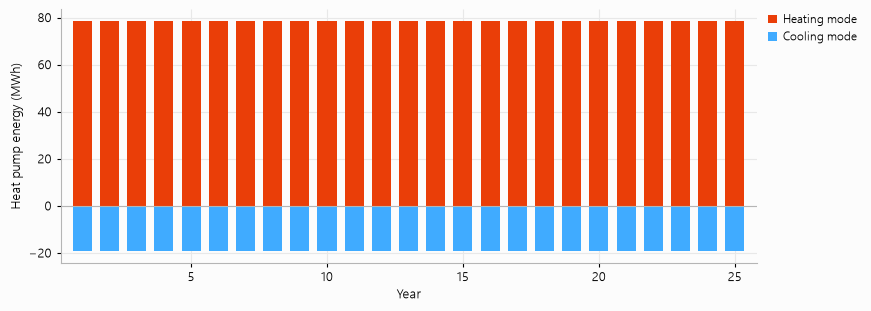

In [19]:
hp = r.hourly.heat_pump_load.reshape(25, 8760)
heating_mwh = np.where(hp > 0, hp, 0).sum(axis=1) / 1000
cooling_mwh = np.where(hp < 0, -hp, 0).sum(axis=1) / 1000

fig, ax = ghe.figure(8.6, 3.0)
ax.bar(years, heating_mwh, color=ghe.RED, width=0.7)
ax.bar(years, -cooling_mwh, color=ghe.BLUE, width=0.7)
ax.axhline(0, color=ghe.AXIS, linewidth=0.8)
ax.set_xlim(0.2, 25.8)
ghe.axis_titles(ax, x="Year", y="Heat pump energy (MWh)")
ghe.legend(ax, [(ghe.RED, "Heating mode"), (ghe.BLUE, "Cooling mode")])

## Inside the borehole

The effective resistance of a borehole depends on the flow through it. The Borehole designer
panel of GHE Analysis draws it, and the plot below does the same, stacked from the four
resistances it is made of. From bottom to top: advective, grout, pipe and
fluid. The dashed line is the flow at which this project operates.

The package returns the equivalent and the effective resistance, the convective one and the pipe
one. The other two are formed from these: the advective resistance is the difference between
the two borehole resistances, and the grout's is what remains of the equivalent resistance once the
pipe and the fluid are taken out.

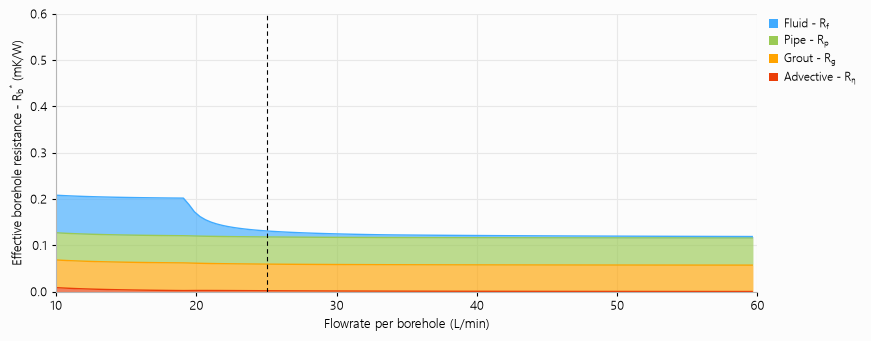

In [20]:
rb = p.compute_borehole_resistance(include_grid=True)
fig = ghecharts.resistance_chart(p, rb)

The step on the left is where the fluid's resistance drops as the flow leaves the laminar regime;
the application's chart has it too. Past it the blue band is thin. More flow changes little, and the grout and
the pipe set the resistance of the borehole.

## The thermal plume

A field cools (or warms) the ground around it. GHE Analysis draws that region in its *Ground heat
exchanger* panel, as bands of colour from blue to red between isotherms. `compute_thermal_plume_2d` returns the same
field on the application's grid, and `ghecharts` fills it with the same hue ramp. Here it is at
years 1, 10 and 25, with bands of half a kelvin:

(-60.0, 70.0)

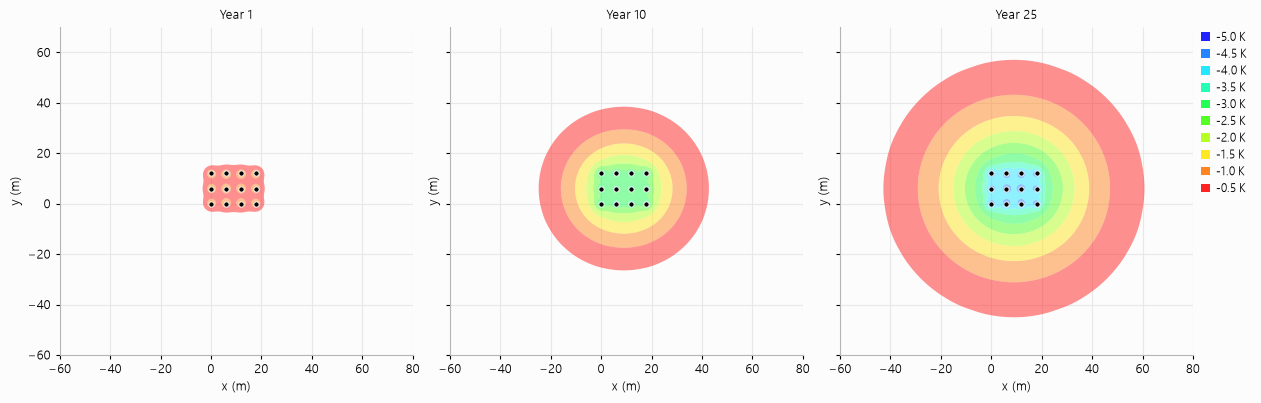

In [21]:
levels = -np.linspace(0.5, 5.0, 10)[::-1]                  # K, from -5.0 to -0.5

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.4), sharex=True, sharey=True)
for ax, year in zip(axes, (1, 10, 25)):
    plume = p.compute_thermal_plume_2d(year * 8760)
    ghecharts.plume2d_panel(ax, p, plume, levels=levels, zoom=False)
    ax.set_title(f"Year {year}", fontsize=9)
ghe.legend(axes[-1], [(c, f"{v:+.1f} K") for c, v in zip(ghe.hue_colours(10), levels)])
axes[0].set_xlim(-60, 80)
axes[0].set_ylim(-60, 70)

A vertical section of the 3D plume shows the same thing in depth: how far down the field reaches,
and how the length of the boreholes shapes it.

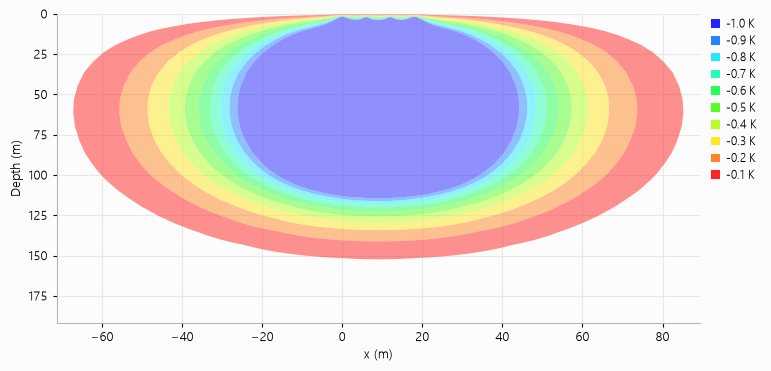

In [22]:
plume3d = p.compute_thermal_plume_3d(25 * 8760)
fig = ghecharts.plume3d_section(p, plume3d)

## Where to go from here

The next notebook, [Sizing a field](02_sizing.ipynb), computes the length of the field and checks
it against simulations like this one. The one after,
[Parametric studies](03_parametric_studies.ipynb), runs hundreds of them.